# Eksplorasi Data (EDA) — IHSG dan Variabel Makroekonomi

Notebook ini melakukan analisis data eksploratif terhadap data yang digunakan
pada pipeline final (multivariate Dual-Branch LSTM), yaitu IHSG dan nilai tukar
(harian) serta inflasi dan BI Rate (bulanan) periode Januari 2015 - Desember 2024.
Sumber data adalah artefak pra-pemrosesan `data/processed_v2/`.

Tujuan EDA: memahami karakteristik statistik tiap variabel, pola pergerakan deret
waktu, hubungan antarvariabel, serta sifat stasioneritas, sebelum tahap pemodelan.
Seluruh keluaran (tabel dan gambar) disimpan ke `reports/figures_v3/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 11

# Temukan root repo secara robust (berjalan dari direktori mana pun di dalam repo)
BASE = Path.cwd()
for cand in [BASE, *BASE.parents]:
    if (cand / "data" / "processed_v2").exists():
        BASE = cand
        break
DATA = BASE / "data" / "processed_v2"
FIGDIR = BASE / "reports" / "figures_v3"
FIGDIR.mkdir(parents=True, exist_ok=True)
print("DATA  :", DATA)
print("FIGDIR:", FIGDIR)

DATA  : D:\project_skripsi\data\processed_v2
FIGDIR: D:\project_skripsi\reports\figures_v3


## 1. Pemuatan Data

In [2]:
d_tr = pd.read_csv(DATA / "df_daily_train.csv", parse_dates=["date"])
d_te = pd.read_csv(DATA / "df_daily_test.csv", parse_dates=["date"])
m_tr = pd.read_csv(DATA / "df_monthly_train.csv", parse_dates=["date"])
m_te = pd.read_csv(DATA / "df_monthly_test.csv", parse_dates=["date"])

daily = pd.concat([d_tr, d_te]).sort_values("date").reset_index(drop=True)
monthly = pd.concat([m_tr, m_te]).sort_values("date").reset_index(drop=True)

print("Data harian :", daily["date"].min().date(), "s.d.", daily["date"].max().date(),
      "| n =", len(daily))
print("Data bulanan:", monthly["date"].min().date(), "s.d.", monthly["date"].max().date(),
      "| n =", len(monthly))
daily.head()

Data harian : 2015-01-02 s.d. 2024-12-30 | n = 2426
Data bulanan: 2015-01-01 s.d. 2024-12-01 | n = 120


,date,ihsg,nilai_tukar
0,2015-01-02,5242.77,12542.5
1,2015-01-05,5219.99,12627.5
2,2015-01-06,5169.06,12657.5
3,2015-01-07,5207.12,12738.5
4,2015-01-08,5211.83,12680.0


## 2. Statistik Deskriptif

Statistik deskriptif memberikan gambaran umum sebaran tiap variabel (jumlah
observasi, nilai minimum dan maksimum, rata-rata, serta standar deviasi).

In [3]:
rows = []
for name, label, freq, s in [
    ("ihsg", "IHSG", "Harian", daily["ihsg"]),
    ("nilai_tukar", "Kurs (USD/IDR)", "Harian", daily["nilai_tukar"]),
    ("inflasi", "Inflasi (%)", "Bulanan", monthly["inflasi"]),
    ("bi_rate", "BI Rate (%)", "Bulanan", monthly["bi_rate"]),
]:
    rows.append({
        "Variabel": label, "Frekuensi": freq, "N": int(s.count()),
        "Minimum": s.min(), "Maksimum": s.max(),
        "Rata-rata": s.mean(), "Std. Deviasi": s.std(),
    })
desc = pd.DataFrame(rows)
desc.to_csv(FIGDIR / "eda_descriptive.csv", index=False)
desc.round(2)

,Variabel,Frekuensi,N,Minimum,Maksimum,Rata-rata,Std. Deviasi
0,IHSG,Harian,2426,3937.63,7905.39,6063.93,844.27
1,Kurs (USD/IDR),Harian,2426,12472.50,16575.00,14318.75,883.45
2,Inflasi (%),Bulanan,120,-0.45,1.17,0.24,0.30
3,BI Rate (%),Bulanan,120,3.50,7.75,5.25,1.24


## 3. Visualisasi Deret Waktu

Pergerakan keempat variabel sepanjang 2015-2024 untuk mengamati tren, musiman,
dan perubahan struktural (antara lain guncangan pada masa pandemi 2020).

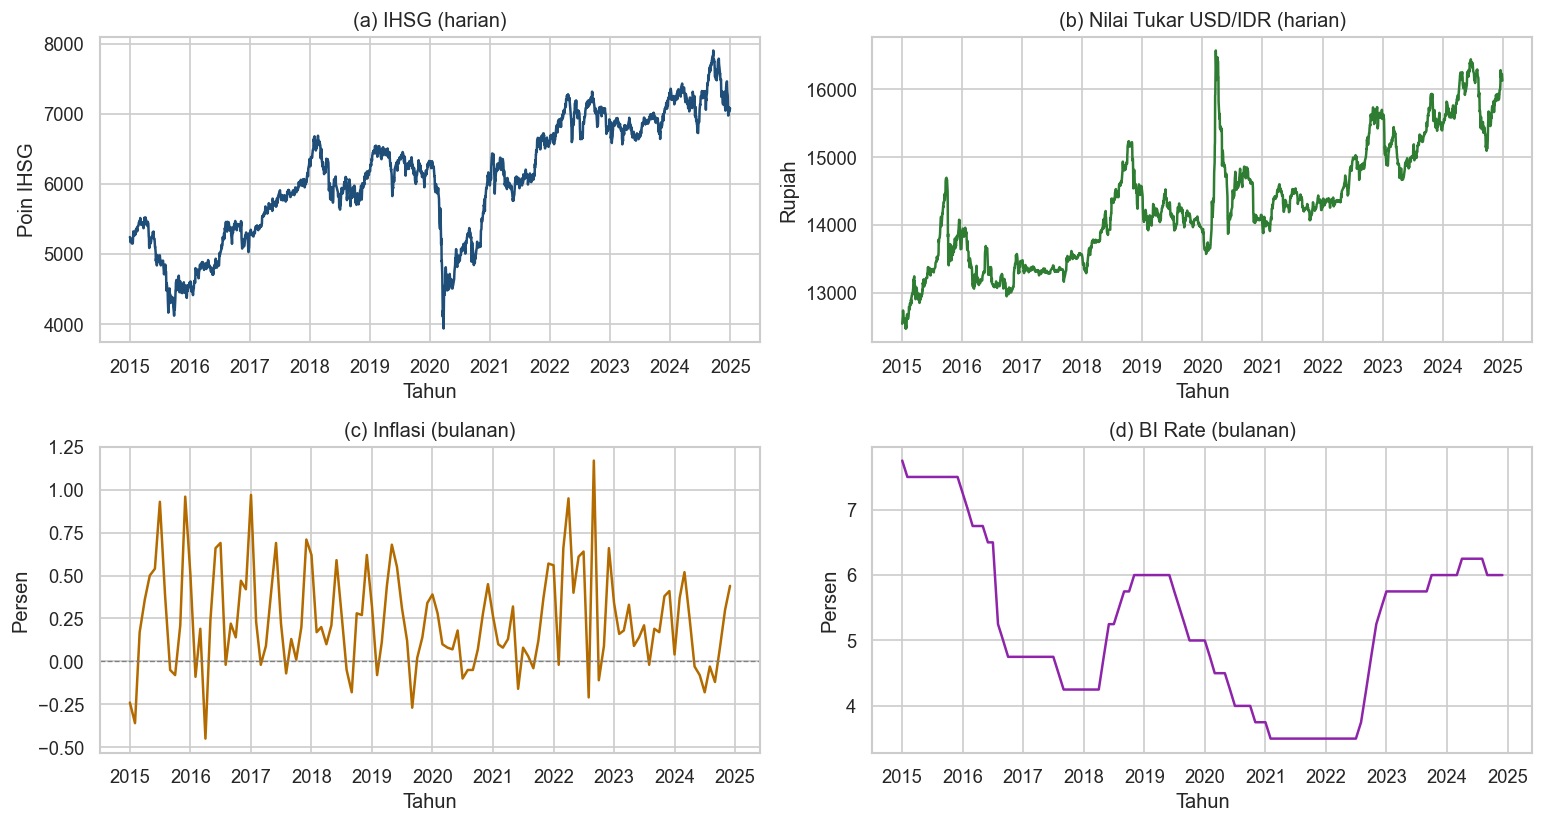

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
axs[0, 0].plot(daily["date"], daily["ihsg"], color="#1f4e79")
axs[0, 0].set_title("(a) IHSG (harian)")
axs[0, 0].set_ylabel("Poin IHSG")
axs[0, 1].plot(daily["date"], daily["nilai_tukar"], color="#2e7d32")
axs[0, 1].set_title("(b) Nilai Tukar USD/IDR (harian)")
axs[0, 1].set_ylabel("Rupiah")
axs[1, 0].plot(monthly["date"], monthly["inflasi"], color="#b36b00")
axs[1, 0].axhline(0, color="gray", lw=0.8, ls="--")
axs[1, 0].set_title("(c) Inflasi (bulanan)")
axs[1, 0].set_ylabel("Persen")
axs[1, 1].plot(monthly["date"], monthly["bi_rate"], color="#8e24aa")
axs[1, 1].set_title("(d) BI Rate (bulanan)")
axs[1, 1].set_ylabel("Persen")
for ax in axs.ravel():
    ax.set_xlabel("Tahun")
fig.tight_layout()
fig.savefig(FIGDIR / "eda_timeseries.png", bbox_inches="tight")
plt.show()

## 4. Korelasi Antarvariabel

Karena dua variabel bersifat bulanan, korelasi dihitung pada **frekuensi bulanan**
(nilai IHSG dan Kurs diagregasi menjadi rata-rata bulanan) agar perbandingan adil
dan tidak menggelembungkan jumlah observasi variabel bulanan.

Observasi bulanan tergabung: 120


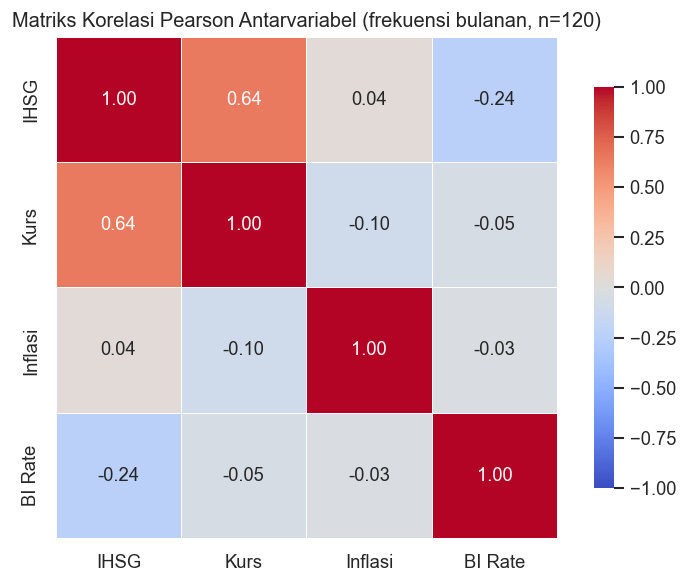

,IHSG,Kurs,Inflasi,BI Rate
IHSG,1.000,0.643,0.036,-0.242
Kurs,0.643,1.000,-0.097,-0.049
Inflasi,0.036,-0.097,1.000,-0.026
BI Rate,-0.242,-0.049,-0.026,1.000


In [5]:
dm = daily.set_index("date")[["ihsg", "nilai_tukar"]].resample("MS").mean()
mm = monthly.set_index("date")[["inflasi", "bi_rate"]].copy()
mm.index = mm.index.values.astype("datetime64[M]").astype("datetime64[ns]")
joined = dm.join(mm, how="inner")
print("Observasi bulanan tergabung:", len(joined))

corr = joined[["ihsg", "nilai_tukar", "inflasi", "bi_rate"]].corr()
corr.columns = ["IHSG", "Kurs", "Inflasi", "BI Rate"]
corr.index = ["IHSG", "Kurs", "Inflasi", "BI Rate"]
corr.to_csv(FIGDIR / "eda_correlation.csv")

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriks Korelasi Pearson Antarvariabel (frekuensi bulanan, n=%d)" % len(joined))
plt.tight_layout()
plt.savefig(FIGDIR / "eda_correlation.png", bbox_inches="tight")
plt.show()
corr.round(3)

## 5. Uji Stasioneritas (Augmented Dickey-Fuller)

Uji ADF dilakukan pada tiap variabel di frekuensi aslinya (IHSG dan Kurs harian;
inflasi dan BI Rate bulanan). Hipotesis nol ADF adalah deret memiliki unit root
(tidak stasioner); nilai-p < 0,05 menolak hipotesis nol (stasioner).

In [6]:
adf_rows = []
for label, freq, s in [
    ("IHSG", "Harian", daily["ihsg"]),
    ("Kurs (USD/IDR)", "Harian", daily["nilai_tukar"]),
    ("Inflasi (%)", "Bulanan", monthly["inflasi"]),
    ("BI Rate (%)", "Bulanan", monthly["bi_rate"]),
]:
    stat, p, *_ = adfuller(s.dropna(), autolag="AIC")
    adf_rows.append({
        "Variabel": label, "Frekuensi": freq,
        "Statistik ADF": round(stat, 3), "nilai-p": round(p, 3),
        "Kesimpulan": "Stasioner" if p < 0.05 else "Tidak stasioner",
    })
adf = pd.DataFrame(adf_rows)
adf.to_csv(FIGDIR / "eda_adf.csv", index=False)
adf

,Variabel,Frekuensi,Statistik ADF,nilai-p,Kesimpulan
0,IHSG,Harian,-1.532,0.518,Tidak stasioner
1,Kurs (USD/IDR),Harian,-2.095,0.246,Tidak stasioner
2,Inflasi (%),Bulanan,-2.343,0.159,Tidak stasioner
3,BI Rate (%),Bulanan,-2.148,0.225,Tidak stasioner


## 6. Autokorelasi (ACF dan PACF)

Fungsi autokorelasi (ACF) dan autokorelasi parsial (PACF) IHSG digunakan untuk
menilai struktur ketergantungan temporal deret sebelum pemodelan. ACF ditinjau
hingga lag 90 hari perdagangan (sepanjang `seq_daily` final), sedangkan PACF
hingga lag 40. Keluaran gambar disimpan sebagai `eda_acf_pacf.png`.

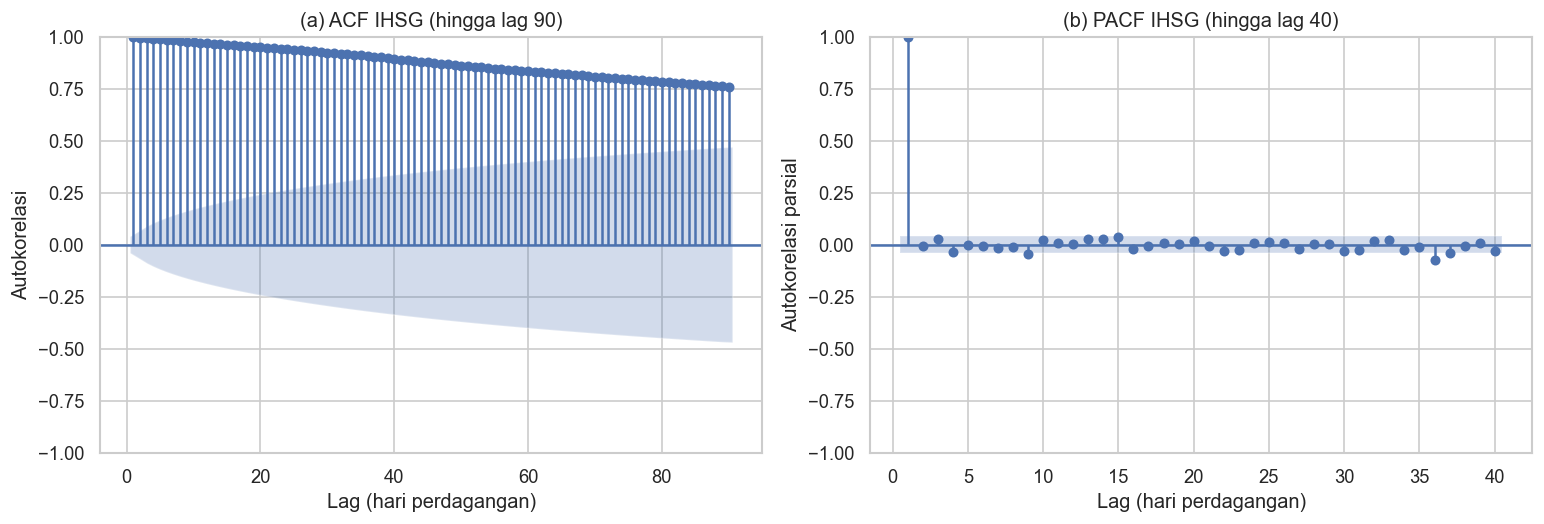

ACF lag 1  : 0.9974
ACF lag 30 : 0.9233
ACF lag 90 : 0.7597


In [7]:
# Autokorelasi IHSG: ACF hingga lag 90 (sepanjang seq_daily final) dan PACF hingga lag 40
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf as _acf

s_ihsg = daily["ihsg"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_acf(s_ihsg, lags=90, ax=axes[0], zero=False)
axes[0].set_title("(a) ACF IHSG (hingga lag 90)")
axes[0].set_xlabel("Lag (hari perdagangan)")
axes[0].set_ylabel("Autokorelasi")
plot_pacf(s_ihsg, lags=40, ax=axes[1], method="ywm", zero=False)
axes[1].set_title("(b) PACF IHSG (hingga lag 40)")
axes[1].set_xlabel("Lag (hari perdagangan)")
axes[1].set_ylabel("Autokorelasi parsial")
fig.tight_layout()
fig.savefig(FIGDIR / "eda_acf_pacf.png", bbox_inches="tight")
plt.show()

# Nilai ACF pada beberapa lag kunci (dirujuk di naskah)
a = _acf(s_ihsg, nlags=90, fft=True)
print(f"ACF lag 1  : {a[1]:.4f}")
print(f"ACF lag 30 : {a[30]:.4f}")
print(f"ACF lag 90 : {a[90]:.4f}")

## 7. Ringkasan Temuan EDA

1. **Skala dan sebaran.** IHSG bergerak pada rentang 3.937-7.905 poin (rata-rata
   6.064) dan Kurs pada 12.473-16.575 Rupiah; inflasi bulanan berkisar -0,45%
   hingga 1,17% (termasuk periode deflasi), sedangkan BI Rate berada pada 3,50%-7,75%.
2. **Pola deret waktu.** IHSG dan Kurs memperlihatkan tren jangka panjang disertai
   guncangan tajam pada masa pandemi 2020; inflasi dan BI Rate bergerak jauh lebih
   lambat (berubah bulanan), mencerminkan karakter indikator makro.
3. **Hubungan antarvariabel.** Korelasi IHSG terhadap Kurs tergolong sedang
   (sekitar 0,64), sedangkan terhadap inflasi (~0,04) dan BI Rate (~-0,24)
   tergolong lemah. Hal ini mengindikasikan keterkaitan linier variabel makro
   terhadap IHSG relatif terbatas pada periode kajian.
4. **Stasioneritas.** Seluruh variabel tidak stasioner pada tingkat (level) pada
   taraf 5%, sehingga pendekatan berbasis sekuens (LSTM) dengan normalisasi menjadi
   wajar digunakan untuk menangkap pola temporal tanpa transformasi diferensi eksplisit.
5. **Autokorelasi.** ACF IHSG meluruh sangat lambat dan masih tinggi (sekitar 0,76
   pada lag 90), sedangkan PACF hanya signifikan pada lag 1 dan mendekati nol
   setelahnya. Pola ini khas deret menyerupai *random walk* dan mendukung
   penggunaan panjang sekuens harian yang cukup besar (`seq_daily=90`).